# Predictive Maintenance of Industrial Equipment Using Machine Learning

**MTech Machine Learning Course Project**

## Project objective
Build and evaluate machine-learning classifiers that predict whether industrial equipment will experience a failure from its operating conditions and sensor measurements.

**Dataset:** AI4I 2020 Predictive Maintenance Dataset (UCI Machine Learning Repository).

**Important methodological note:** The dataset includes individual failure-mode indicators (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`). These are not used as predictors because they are closely tied to the target `Machine failure` and would cause target leakage.

## 1. Import libraries

If a package is missing, install it in a separate notebook cell using `%pip install package-name`, then restart the kernel if requested.

In [5]:
%pip install --force-reinstall numpy==1.26.4 shap==0.46.0 matplotlib==3.8.4

  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached shap-0.46.0-cp312-cp312-win_amd64.whl.metadata (25 kB)
  Using cached matplotlib-3.8.4-cp312-cp312-win_amd64.whl.metadata (5.9 kB)
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached pandas-3.1.1-cp312-cp312-win_amd64.whl.metadata (16 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached packaging-26.3-py3-none-any.whl.metadata (3.5 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
  Using cached numba-0.68.1-cp312-cp312-win_amd64.whl.metadata (2.9 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp312-cp312-win_amd64.whl.metadata (142 kB)
  Using cached kiwi

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
botocore 1.34.69 requires python-dateutil<3.0.0,>=2.1, but you have python-dateutil 4.0.0 which is incompatible.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.17.1 which is incompatible.
streamlit 1.37.1 requires packaging<25,>=20, but you have packaging 26.3 which is incompatible.
streamlit 1.37.1 requires pandas<3,>=1.3.0, but you have pandas 3.0.6 which is incompatible.
streamlit 1.37.1 requires pillow<11,>=7.1.0, but you have pillow 13.0.0 which is incompatible.


In [6]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load the dataset

Place the extracted `ai4i2020.csv` file in the same folder as this notebook, or update `DATA_PATH` below. The loader also checks a `dataset` subfolder.

In [10]:
DATA_PATH = Path("ai4i2020.csv")

if not DATA_PATH.exists():
    candidates = list(Path(".").glob("**/ai4i2020.csv"))
    if candidates:
        DATA_PATH = candidates[0]
    else:
        raise FileNotFoundError(
            "Could not find ai4i2020.csv. Extract the dataset ZIP and place "
            "ai4i2020.csv beside this notebook, or update DATA_PATH."
        )

df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Loaded: ai4i2020.csv
Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 3. Initial dataset understanding

Inspect column names, data types, missing values, duplicate rows and descriptive statistics.

In [13]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("missing_values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                 

,missing_values
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0



Duplicate rows: 0

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,M14860,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0


## 4. Target variable and class balance

The target is `Machine failure`. This is a binary classification problem: 0 = no failure, 1 = failure.

Because failures are relatively rare, accuracy alone is not a sufficient evaluation metric. We will pay particular attention to recall, precision, F1-score and average precision (PR-AUC).

,count
Machine failure,
0,9661
1,339


,percentage
Machine failure,
0,96.61
1,3.39


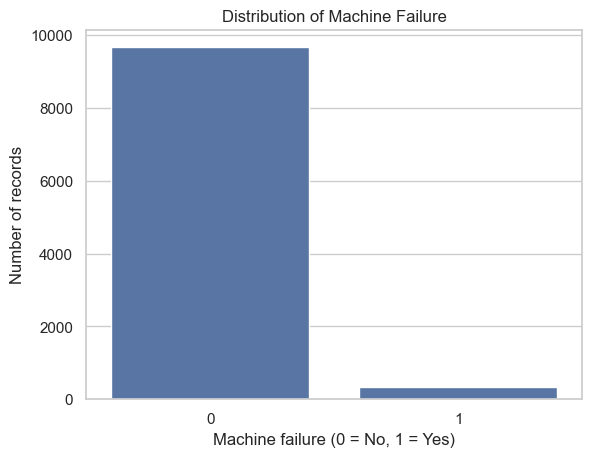

In [16]:
TARGET = "Machine failure"
if TARGET not in df.columns:
    raise ValueError(f"Expected target column '{TARGET}' was not found.")

display(df[TARGET].value_counts().rename("count").to_frame())
display((df[TARGET].value_counts(normalize=True) * 100).rename("percentage").to_frame())

ax = sns.countplot(data=df, x=TARGET)
ax.set_title("Distribution of Machine Failure")
ax.set_xlabel("Machine failure (0 = No, 1 = Yes)")
ax.set_ylabel("Number of records")
plt.show()

## 5. Exploratory Data Analysis

The following plots explore sensor distributions and how operating conditions relate to the failure label. These are exploratory associations, not proof of causation.

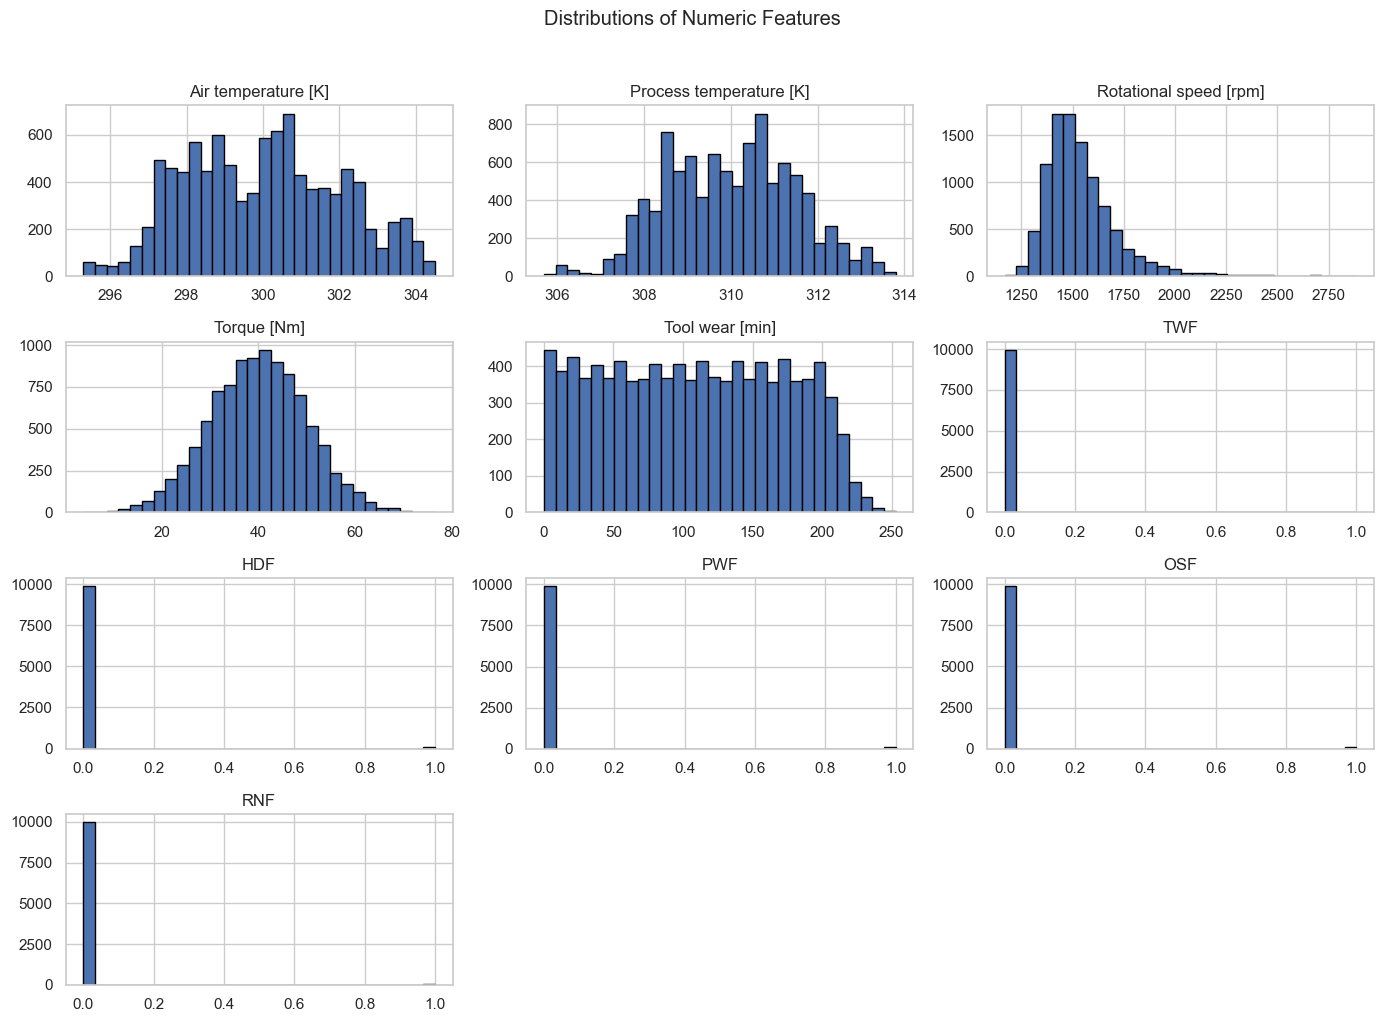

In [19]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_features_for_plot = [
    c for c in numeric_cols
    if c not in [TARGET, "UDI"]
]

df[numeric_features_for_plot].hist(figsize=(14, 10), bins=30, edgecolor="black")
plt.suptitle("Distributions of Numeric Features", y=1.02)
plt.tight_layout()
plt.show()

,failure_rate
Type,
L,0.039167
M,0.027694
H,0.020937


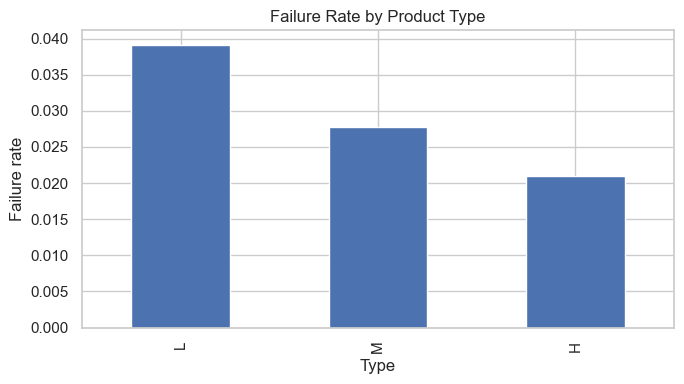

In [20]:
# Failure rate by product type
if "Type" in df.columns:
    failure_by_type = df.groupby("Type")[TARGET].mean().sort_values(ascending=False)
    display(failure_by_type.rename("failure_rate").to_frame())
    failure_by_type.plot(kind="bar", figsize=(7, 4), title="Failure Rate by Product Type")
    plt.ylabel("Failure rate")
    plt.tight_layout()
    plt.show()

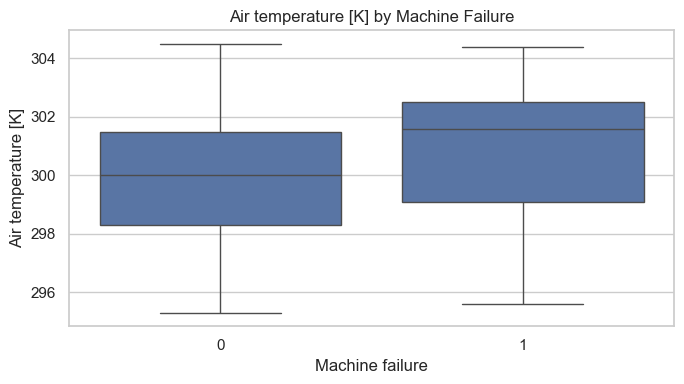

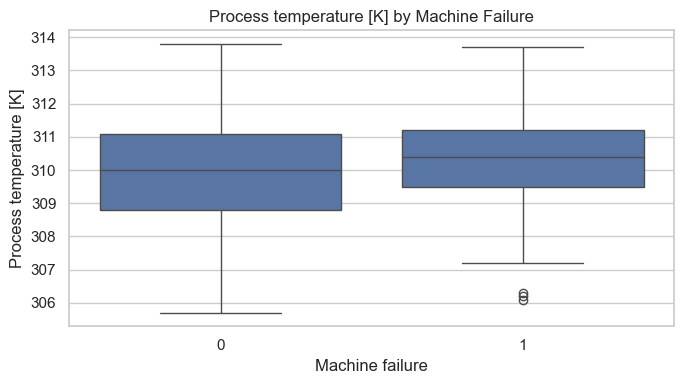

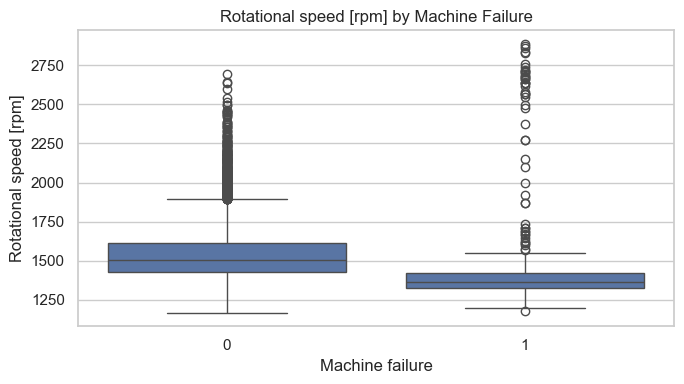

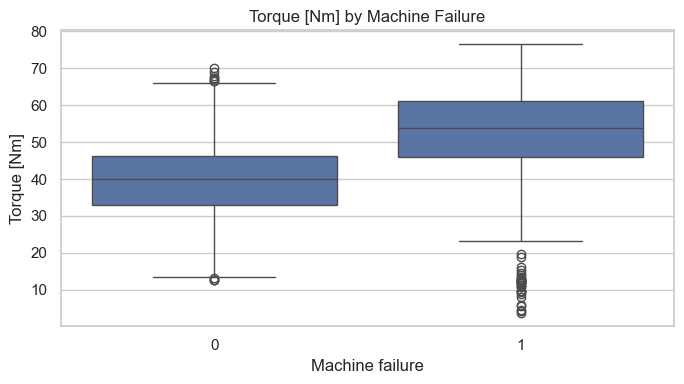

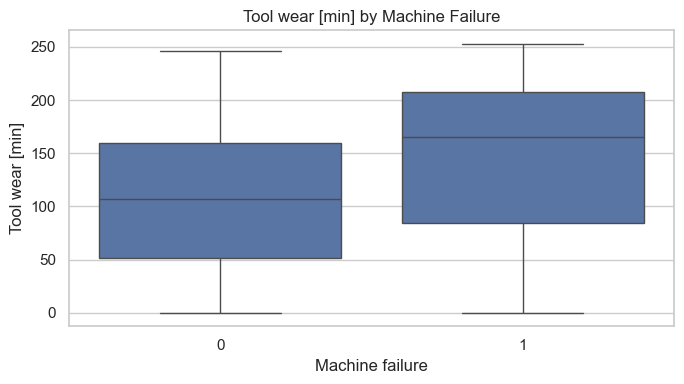

In [23]:
# Sensor distributions split by target
sensor_candidates = [
    "Air temperature [K]", "Process temperature [K]",
    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"
]
available_sensors = [c for c in sensor_candidates if c in df.columns]

for col in available_sensors:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=TARGET, y=col)
    plt.title(f"{col} by Machine Failure")
    plt.tight_layout()
    plt.show()

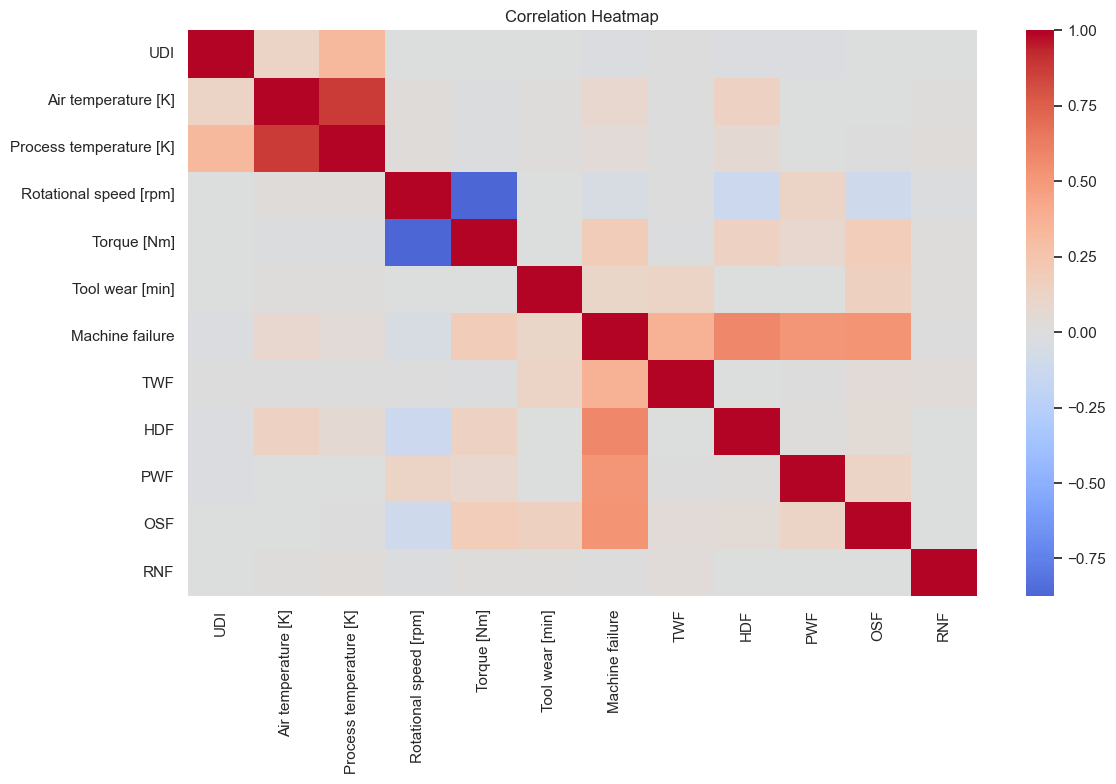

In [25]:
# Correlation heatmap for numeric variables
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 6. Data preparation and leakage prevention

We remove:
- `Machine failure`: the target itself.
- `UDI`: row identifier, not a useful operating measurement.
- `Product ID`: unique product identifier.
- `TWF`, `HDF`, `PWF`, `OSF`, `RNF`: failure-mode labels that can leak target information.

The remaining operational features, including `Type`, are used as predictors. We split the data before fitting preprocessing steps so information from the test set does not influence training.

In [28]:
drop_candidates = [
    "UDI", "Product ID",
    "TWF", "HDF", "PWF", "OSF", "RNF"
]
drop_existing = [c for c in drop_candidates if c in df.columns]

X = df.drop(columns=[TARGET] + drop_existing)
y = df[TARGET].astype(int)

print("Dropped columns:", drop_existing)
print("Predictor columns:", X.columns.tolist())
print("\nTarget distribution:")
print(y.value_counts())

Dropped columns: ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Predictor columns: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Training rows: 8000
Test rows: 2000
Numerical features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Categorical features: ['Type']


## 7. Establish a simple baseline

A dummy classifier provides a reference point. A useful model should improve on this baseline, especially on minority-class detection.

In [33]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print(classification_report(y_test, baseline_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



## 8. Train and compare machine-learning models

We compare Logistic Regression, Decision Tree, Random Forest and HistGradientBoosting. The first three use a preprocessing pipeline. HistGradientBoosting is omitted here because it does not directly accept the sparse one-hot output; XGBoost is added separately below if installed.

In [36]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE, max_depth=8
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=2
    )
}

results = []
fitted_models = {}

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, proba),
        "PR_AUC": average_precision_score(y_test, proba)
    }
    results.append(row)
    fitted_models[name] = pipe

results_df = pd.DataFrame(results).sort_values("PR_AUC", ascending=False)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
2,Random Forest,0.9735,0.5824,0.7794,0.6667,0.9669,0.7543
1,Decision Tree,0.9535,0.4088,0.8235,0.5463,0.9006,0.6691
0,Logistic Regression,0.8245,0.1418,0.8235,0.2419,0.9070,0.3818


In [41]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   -- ------------------------------------- 3.1/48.9 MB 12.3 MB/s eta 0:00:04
   --- ------------------------------------ 3.9/48.9 MB 14.7 MB/s eta 0:00:04
   -------- ------------------------------- 10.0/48.9 MB 15.5 MB/s eta 0:00:03
   --------- ------------------------------ 11.5/48.9 MB 13.4 MB/s eta 0:00:03
   ------------ --------------------------- 14.9/48.9 MB 14.7 MB/s eta 0:00:03
   -------------- ------------------------- 18.1/48.9 MB 14.1 MB/s eta 0:00:03
   ---------------- ----------------------- 20.4/48.9 MB 13.7 MB/s eta 0:00:03
   ----------------- ---------------------- 22.0/48.9 MB 13.3 MB/s eta 0:00:03
   ------------------ --------------------- 23.1/48.9 MB 12.1 MB/s eta 0:00:03
   ------------------- -------------------- 23.6/48.9 MB 11.4 MB/s eta 0:00:03
   ------------------- -------------------- 24.4/48.9 MB 10.5 MB/s eta 0

## 9. Optional: XGBoost model

If XGBoost is installed, this section trains an additional gradient-boosting classifier. If it is unavailable, the notebook continues without it.

If needed, run `%pip install xgboost` in a separate cell and restart the kernel.

In [49]:
try:
    from xgboost import XGBClassifier

    # Compute a training-only class ratio for imbalance handling.
    negatives = int((y_train == 0).sum())
    positives = int((y_train == 1).sum())
    scale_pos_weight = negatives / max(positives, 1)

    xgb_pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(
            n_estimators=350,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            objective="binary:logistic",
            eval_metric="logloss",
            scale_pos_weight=scale_pos_weight,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

    xgb_pipe.fit(X_train, y_train)
    xgb_pred = xgb_pipe.predict(X_test)
    xgb_proba = xgb_pipe.predict_proba(X_test)[:, 1]

    xgb_row = {
        "Model": "XGBoost",
        "Accuracy": accuracy_score(y_test, xgb_pred),
        "Precision": precision_score(y_test, xgb_pred, zero_division=0),
        "Recall": recall_score(y_test, xgb_pred, zero_division=0),
        "F1": f1_score(y_test, xgb_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, xgb_proba),
        "PR_AUC": average_precision_score(y_test, xgb_proba)
    }
    results.append(xgb_row)
    fitted_models["XGBoost"] = xgb_pipe
    results_df = pd.DataFrame(results).sort_values("PR_AUC", ascending=False)
    print("XGBoost trained successfully.")
    display(results_df.round(4))

except ImportError:
    print("XGBoost is not installed. Run %pip install xgboost, restart the kernel, and rerun this section if time permits.")

XGBoost trained successfully.


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
3,XGBoost,0.9725,0.5670,0.8088,0.6667,0.9712,0.8232
4,XGBoost,0.9725,0.5670,0.8088,0.6667,0.9712,0.8232
2,Random Forest,0.9735,0.5824,0.7794,0.6667,0.9669,0.7543
1,Decision Tree,0.9535,0.4088,0.8235,0.5463,0.9006,0.6691
0,Logistic Regression,0.8245,0.1418,0.8235,0.2419,0.9070,0.3818


## 10. Model comparison visualization

Compare the models using metrics that matter for the minority failure class. The best model should not be selected using accuracy alone.

,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,
XGBoost,0.5670,0.8088,0.6667,0.9712,0.8232
XGBoost,0.5670,0.8088,0.6667,0.9712,0.8232
Random Forest,0.5824,0.7794,0.6667,0.9669,0.7543
Decision Tree,0.4088,0.8235,0.5463,0.9006,0.6691
Logistic Regression,0.1418,0.8235,0.2419,0.9070,0.3818


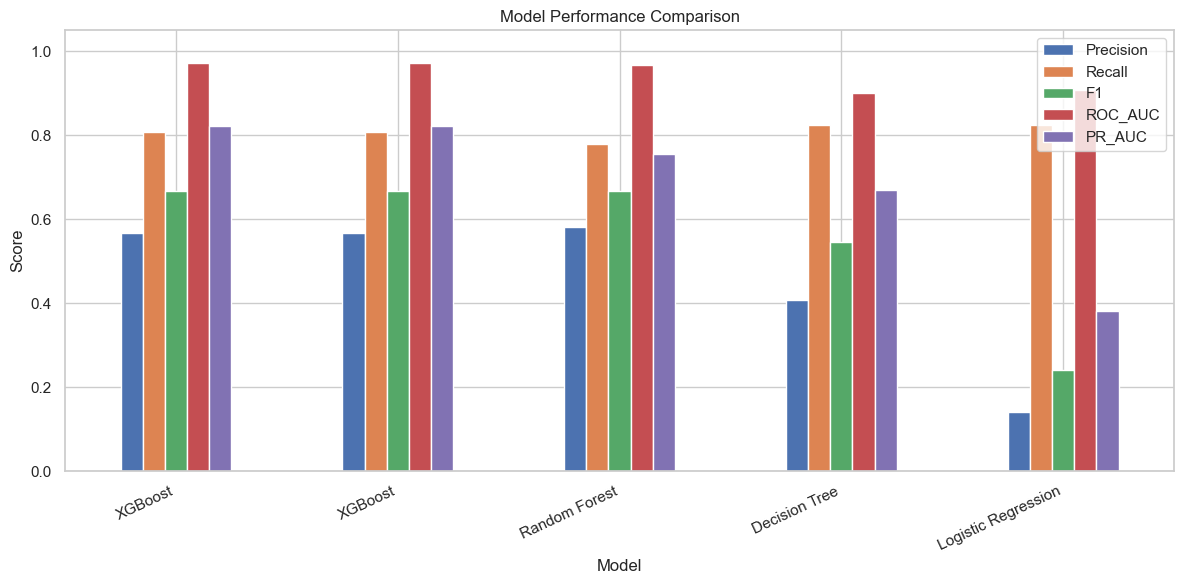

In [52]:
metrics_to_plot = ["Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]
plot_df = results_df.set_index("Model")[metrics_to_plot]
display(plot_df.round(4))

plot_df.plot(kind="bar", figsize=(12, 6))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 11. Detailed evaluation of the selected model

For this imbalanced classification problem, select the model with the strongest PR-AUC as an initial choice, then inspect its precision and recall trade-off. The selected model is not necessarily the one with the highest accuracy.

Selected model: XGBoost

Classification report:
              precision    recall  f1-score   support

  No Failure       0.99      0.98      0.99      1932
     Failure       0.57      0.81      0.67        68

    accuracy                           0.97      2000
   macro avg       0.78      0.89      0.83      2000
weighted avg       0.98      0.97      0.97      2000



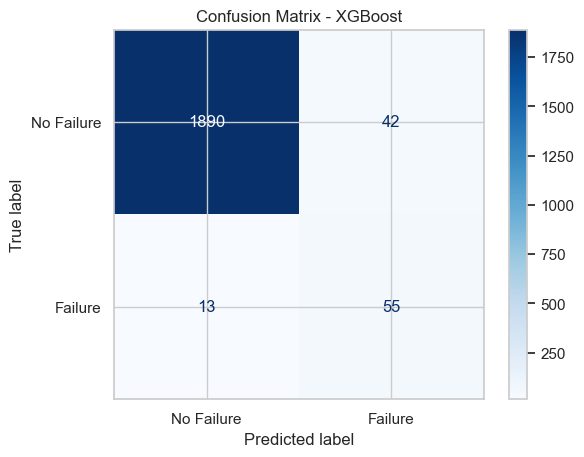

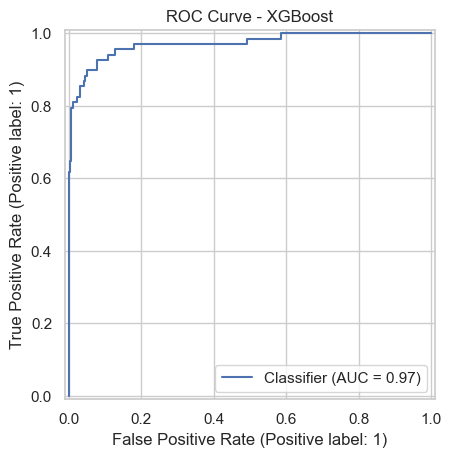

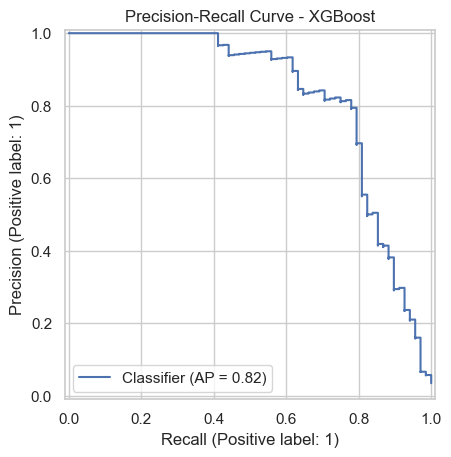

In [55]:
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

best_pred = best_model.predict(X_test)
best_proba = best_model.predict_proba(X_test)[:, 1]

print("Selected model:", best_model_name)
print("\nClassification report:")
print(classification_report(y_test, best_pred, target_names=["No Failure", "Failure"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred,
    display_labels=["No Failure", "Failure"],
    cmap="Blues"
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

RocCurveDisplay.from_predictions(y_test, best_proba)
plt.title(f"ROC Curve - {best_model_name}")
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, best_proba)
plt.title(f"Precision-Recall Curve - {best_model_name}")
plt.show()

## 12. Hyperparameter tuning (Random Forest)

This section tunes a Random Forest pipeline using stratified cross-validation and average precision. It may take a few minutes depending on your computer.

In [58]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

param_distributions = {
    "model__n_estimators": [150, 250, 350],
    "model__max_depth": [None, 6, 10, 14],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="average_precision",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)
print("Best cross-validation PR-AUC:", round(search.best_score_, 4))

tuned_rf = search.best_estimator_
tuned_pred = tuned_rf.predict(X_test)
tuned_proba = tuned_rf.predict_proba(X_test)[:, 1]

print("\nTuned Random Forest test results:")
print(classification_report(y_test, tuned_pred, target_names=["No Failure", "Failure"], zero_division=0))
print("PR-AUC:", round(average_precision_score(y_test, tuned_proba), 4))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'model__n_estimators': 350, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_depth': None}
Best cross-validation PR-AUC: 0.7253

Tuned Random Forest test results:
              precision    recall  f1-score   support

  No Failure       0.99      0.98      0.99      1932
     Failure       0.58      0.78      0.67        68

    accuracy                           0.97      2000
   macro avg       0.79      0.88      0.83      2000
weighted avg       0.98      0.97      0.98      2000

PR-AUC: 0.7548


## 13. Feature importance

Random Forest feature importance helps identify which inputs contributed most to the fitted model. Importance is model-dependent and should not be interpreted as proof of causation.

,Feature,Importance
3,num__Torque [Nm],0.318093
2,num__Rotational speed [rpm],0.296965
4,num__Tool wear [min],0.205653
0,num__Air temperature [K],0.097394
1,num__Process temperature [K],0.065025
6,cat__Type_L,0.008130
7,cat__Type_M,0.005942
5,cat__Type_H,0.002798


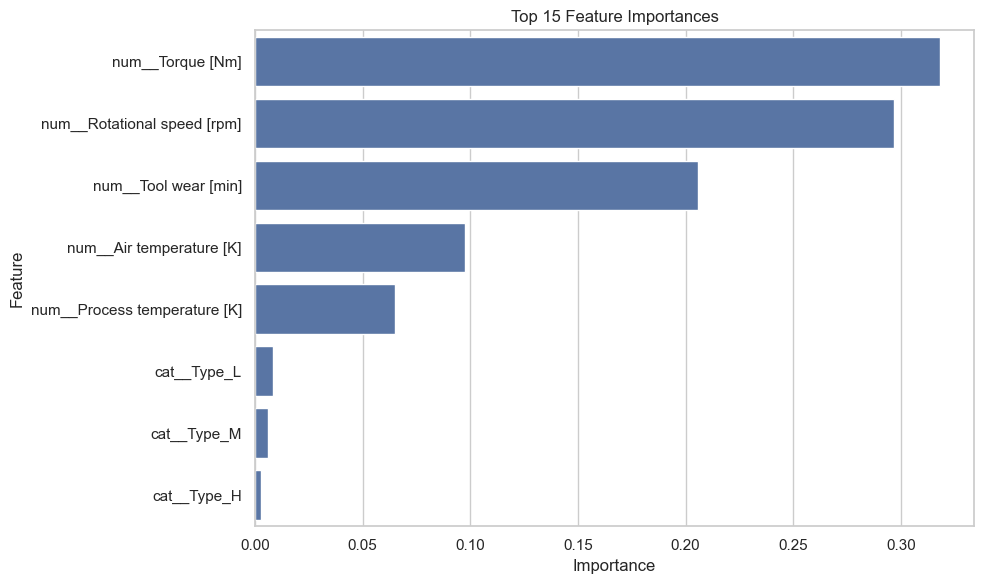

In [61]:
# Use the tuned Random Forest if available; otherwise use the original Random Forest.
importance_model = tuned_rf if "tuned_rf" in globals() else fitted_models.get("Random Forest")

if importance_model is not None:
    fitted_preprocessor = importance_model.named_steps["preprocessor"]
    fitted_estimator = importance_model.named_steps["model"]
    feature_names = fitted_preprocessor.get_feature_names_out()
    importances = fitted_estimator.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False)

    display(importance_df.head(15))

    plt.figure(figsize=(10, 6))
    sns.barplot(data=importance_df.head(15), x="Importance", y="Feature")
    plt.title("Top 15 Feature Importances")
    plt.tight_layout()
    plt.show()

## 14. Optional SHAP explainability

SHAP provides a more detailed explanation of model predictions. This is optional if installation or runtime is an issue before submission.

Run `%pip install shap` in a separate cell if needed.

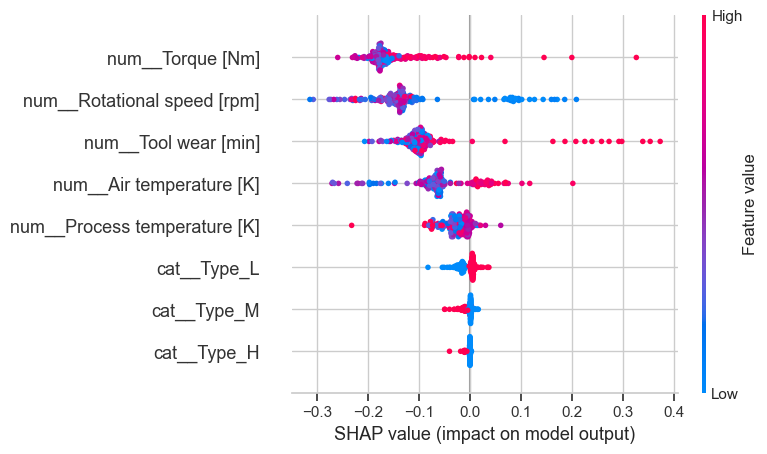

In [63]:
try:
    import shap

    # Explain a small sample to keep computation manageable.
    X_sample = X_test.sample(min(200, len(X_test)), random_state=RANDOM_STATE)
    transformed_sample = importance_model.named_steps["preprocessor"].transform(X_sample)

    explainer = shap.TreeExplainer(importance_model.named_steps["model"])
    shap_values = explainer.shap_values(transformed_sample)

    if isinstance(shap_values, list):
        shap_values_to_plot = shap_values[-1]
    elif getattr(shap_values, "ndim", 0) == 3:
        shap_values_to_plot = shap_values[:, :, -1]
    else:
        shap_values_to_plot = shap_values

    shap.summary_plot(
        shap_values_to_plot,
        transformed_sample,
        feature_names=importance_model.named_steps["preprocessor"].get_feature_names_out(),
        show=True
    )
except ImportError:
    print("SHAP is not installed. Run %pip install shap if time permits.")
except Exception as e:
    print("SHAP section could not be completed:", repr(e))

## 15. Save the trained model and results

The model file and comparison table can be included in the project repository. Do not commit very large generated files unless required by your course.

In [67]:
import joblib

joblib.dump(best_model, "predictive_maintenance_model.joblib")
results_df.to_csv("model_comparison_results.csv", index=False)

print("Saved predictive_maintenance_model.joblib")
print("Saved model_comparison_results.csv")

Saved predictive_maintenance_model.joblib
Saved model_comparison_results.csv


## 16. Conclusion

Complete this section after running all notebook cells. Use the actual values printed in the model comparison and evaluation sections.

Suggested points to discuss:
- The project framed machine failure prediction as a binary classification task.
- The AI4I dataset was explored and preprocessed.
- Multiple classification algorithms were compared using a stratified train/test split.
- Precision, recall, F1-score, ROC-AUC and PR-AUC were used because the target classes are imbalanced.
- Failure-mode columns were excluded to avoid target leakage.
- Feature importance was used to interpret the fitted model.
- Limitations include the synthetic nature of the AI4I dataset and the fact that results on this dataset may not directly generalize to real factory equipment.

**Important:** Do not invent or copy model scores into your report. Record the results produced by your own notebook run.

In [52]:
%pip install shap